In [1]:

# Step 1: Import required libraries

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report


In [2]:

# Step 2: Load the Wine dataset

wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="target")

print("Dataset shape:", X.shape)
print("\nFirst five rows:")
display(X.head())

print("\nTarget classes:")
print(pd.Series(y).value_counts().sort_index())

print("\nClass names:", wine.target_names)


Dataset shape: (178, 13)

First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Target classes:
target
0    59
1    71
2    48
Name: count, dtype: int64

Class names: ['class_0' 'class_1' 'class_2']


In [3]:

# Step 3: Split the data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 142
Testing samples: 36


In [4]:

# Step 4: Train the baseline model

rf_all = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_all.fit(X_train, y_train)

# Predict on the test data
y_pred_all = rf_all.predict(X_test)

# Evaluate the model
accuracy_all = accuracy_score(y_test, y_pred_all)

print("Baseline Model - All Features")
print("Number of features:", X_train.shape[1])
print("Accuracy:", round(accuracy_all, 4))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_all,
    target_names=wine.target_names
))


Baseline Model - All Features
Number of features: 13
Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



In [5]:

# Step 5: Calculate feature importance

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_all.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Feature Importance Ranking:")
display(importance_df)


Feature Importance Ranking:


,Feature,Importance
0,color_intensity,0.187580
1,flavanoids,0.159561
2,proline,0.146799
3,alcohol,0.117913
4,hue,0.101538
5,od280/od315_of_diluted_wines,0.096301
6,total_phenols,0.041514
7,magnesium,0.040131
8,malic_acid,0.033894
9,alcalinity_of_ash,0.025471


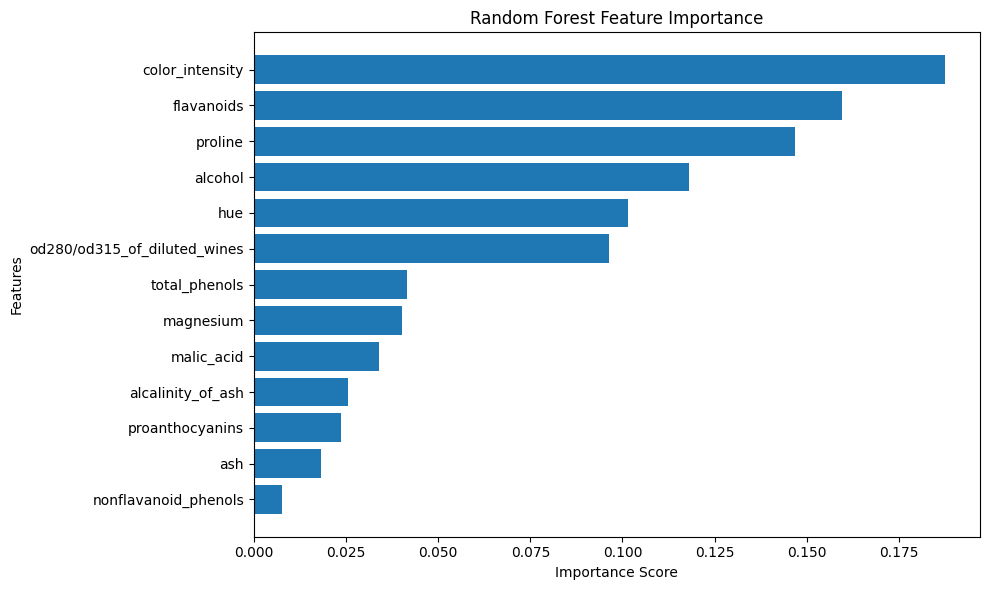

In [6]:

# Step 6: Plot feature importance

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [7]:

# Step 7: Select top five features

top_5_features = importance_df["Feature"].head(5).tolist()

print("Top 5 Selected Features:")
for feature in top_5_features:
    print("-", feature)

# Create reduced datasets
X_train_top5 = X_train[top_5_features]
X_test_top5 = X_test[top_5_features]

print("\nTraining data shape:", X_train_top5.shape)
print("Testing data shape:", X_test_top5.shape)


Top 5 Selected Features:
- color_intensity
- flavanoids
- proline
- alcohol
- hue

Training data shape: (142, 5)
Testing data shape: (36, 5)


In [8]:

# Step 8: Train model using top five features

rf_top5 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_top5.fit(X_train_top5, y_train)

# Make predictions
y_pred_top5 = rf_top5.predict(X_test_top5)

# Evaluate the model
accuracy_top5 = accuracy_score(y_test, y_pred_top5)

print("Random Forest - Top 5 Features")
print("Number of features:", len(top_5_features))
print("Accuracy:", round(accuracy_top5, 4))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_top5,
    target_names=wine.target_names
))


Random Forest - Top 5 Features
Number of features: 5
Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



Model Comparison:


,Model,Number of Features,Accuracy,Accuracy (%)
0,Random Forest - All Features,13,1.0,100.0
1,Random Forest - Top 5 Features,5,1.0,100.0


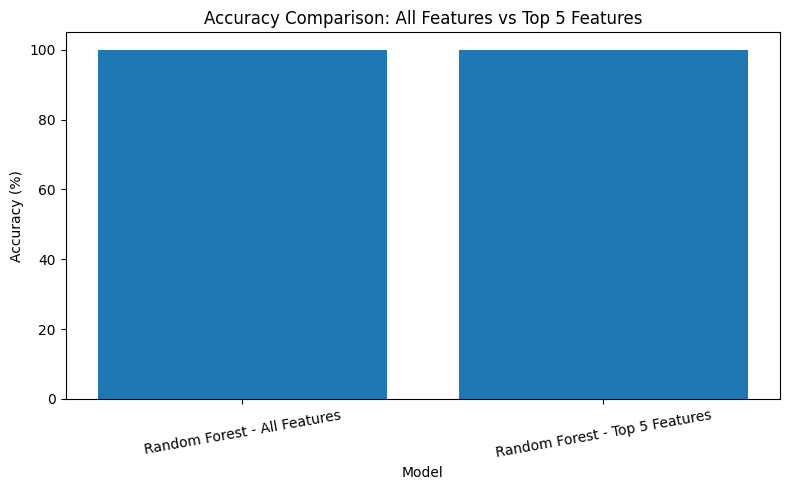


Accuracy difference (percentage points): 0.0


In [9]:

# Step 9: Compare model performance

comparison = pd.DataFrame({
    "Model": [
        "Random Forest - All Features",
        "Random Forest - Top 5 Features"
    ],
    "Number of Features": [
        X_train.shape[1],
        len(top_5_features)
    ],
    "Accuracy": [
        accuracy_all,
        accuracy_top5
    ]
})

comparison["Accuracy (%)"] = (
    comparison["Accuracy"] * 100
).round(2)

print("Model Comparison:")
display(comparison)

# Plot accuracy comparison
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy (%)"]
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("Accuracy Comparison: All Features vs Top 5 Features")
plt.ylim(0, 105)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

print(
    "\nAccuracy difference (percentage points):",
    round((accuracy_top5 - accuracy_all) * 100, 2)
)


In [10]:

# Step 10: Final experiment summary

print("=" * 45)
print("RANDOM FOREST FEATURE SELECTION SUMMARY")
print("=" * 45)

print(f"Total original features: {X.shape[1]}")
print(f"Selected features: {len(top_5_features)}")

print("\nTop 5 Features:")
for feature in top_5_features:
    print("-", feature)

print(f"\nBaseline accuracy: {accuracy_all * 100:.2f}%")
print(f"Top 5 accuracy: {accuracy_top5 * 100:.2f}%")

difference = (accuracy_top5 - accuracy_all) * 100

print(f"Accuracy difference: {difference:+.2f} percentage points")

if difference > 0:
    print("Observation: Accuracy increased with the top five features.")
elif difference < 0:
    print("Observation: Accuracy decreased with the top five features.")
else:
    print("Observation: Both models achieved the same accuracy.")

print("\nConclusion:")
print("Feature selection reduced the number of input features")
print("from 13 to 5. Compare the measured accuracies to decide")
print("whether the reduction retained predictive performance.")


RANDOM FOREST FEATURE SELECTION SUMMARY
Total original features: 13
Selected features: 5

Top 5 Features:
- color_intensity
- flavanoids
- proline
- alcohol
- hue

Baseline accuracy: 100.00%
Top 5 accuracy: 100.00%
Accuracy difference: +0.00 percentage points
Observation: Both models achieved the same accuracy.

Conclusion:
Feature selection reduced the number of input features
from 13 to 5. Compare the measured accuracies to decide
whether the reduction retained predictive performance.
